In [6]:
!pip install --upgrade pandas numpy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USER\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
df = pd.read_csv('social_media_engagement_5000.csv')
print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [8]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [9]:
print(df.describe())

            user_id          age        post_id         likes     comments  \
count   5000.000000  4850.000000    5000.000000   4850.000000  4850.000000   
mean   54561.890800    38.454021  548042.909000  10107.043711  1502.195670   
std    26090.370121    14.912381  260646.957267   5789.819252   869.537889   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5068.500000   760.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  15115.000000  2256.000000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   

            shares  watch_time_sec  impression_count  follower_count  \
count  4850.000000     5000.000000       5000.000000     5000.000000   
mean   1002.629485     4014.503200      50013.732800   393698.224800   
std     579.615158     2308.096459      28844.939104   230927.884535   
min      

In [10]:
print("missing value:n",df.isnull().sum())
duplicates = df.duplicated().sum() 
print("\n duplicate rows count:",duplicates)
df= df.drop_duplicates()

missing value:n user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

 duplicate rows count: 0


In [11]:
print("dataset shape(rows,coloumns):",df.shape)
print("\ncolumn names:\n",df.columns)
print("\ndataset info:")
print(df.info())
print("\npost type value counts:\n",df['post_type'].value_counts())

dataset shape(rows,coloumns): (5000, 19)

column names:
 Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64

In [12]:
print("missing values before cleaning:\n",df.isnull().sum())
df = df.dropna()
print("\nmissing values after cleaning:\n",df.isnull().sum())
print("\nnew dataset shape:",df.shape)

missing values before cleaning:
 user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

missing values after cleaning:
 user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

new dataset shape: (4162, 19)


In [19]:
df['engagement_score'] = df['comments'] + df['shares']
print(("--- mean values---"))
print(df[['comments','shares','follower_count']].mean())
print("\n--- meadian values---")
print(df[['comments','shares','follower_count']].median())

--- mean values---
comments            1502.600913
shares               999.359202
follower_count    394707.644402
dtype: float64

--- meadian values---
comments            1505.5
shares              1007.0
follower_count    390905.5
dtype: float64


In [8]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')


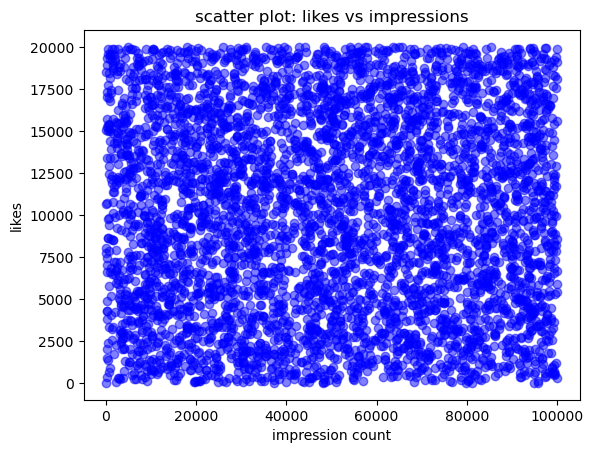

In [9]:
import matplotlib.pyplot as plt
plt.Figure(figsize=(8, 5))
plt.scatter(df['impression_count'],df['likes'],color='blue', alpha=0.5)
plt.title('scatter plot: likes vs impressions')
plt.xlabel('impression count')
plt.ylabel('likes')
plt.show()

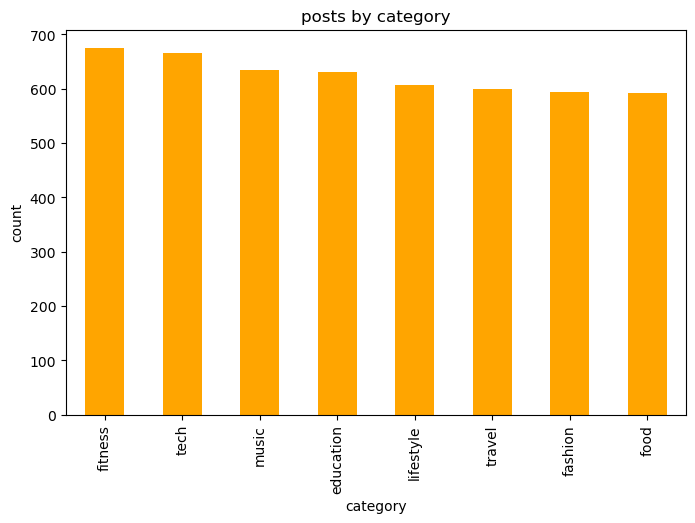

In [10]:
plt.figure(figsize=(8, 5))
df['post_category'].value_counts().plot(kind='bar', color='orange')
plt.title('posts by category')
plt.xlabel('category')
plt.ylabel('count')
plt.show()

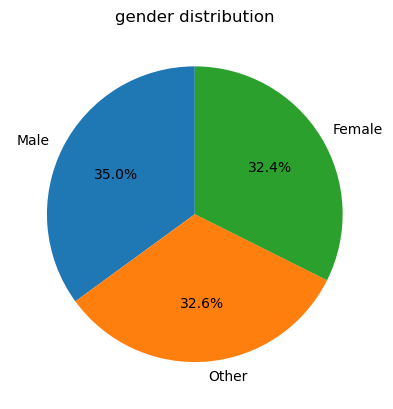

In [11]:
plt.Figure(figsize=(6,6))
df['gender'].value_counts().plot(kind='pie',autopct='%1.1f%%',startangle=90)
plt.title('gender distribution')
plt.ylabel('')
plt.show()

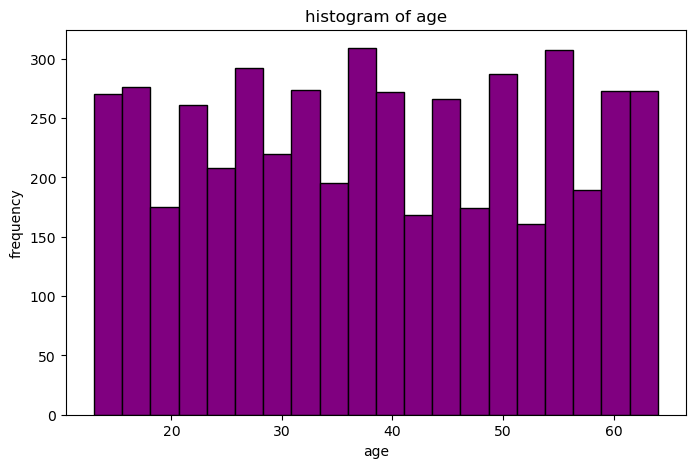

In [12]:
plt.figure(figsize=(8,5))
plt.hist(df['age'].dropna(), bins=20, color='purple',edgecolor='black')
plt.title('histogram of age')
plt.xlabel('age')
plt.ylabel('frequency')
plt.show()

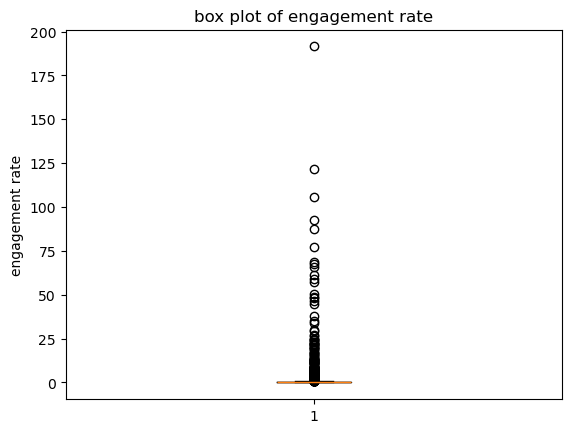

In [14]:
plt.Figure(figsize=(6, 5))
plt.boxplot(df['engagement_rate'].dropna())
plt.title('box plot of engagement rate')
plt.ylabel('engagement rate')
plt.show()

In [15]:
import seaborn as sns

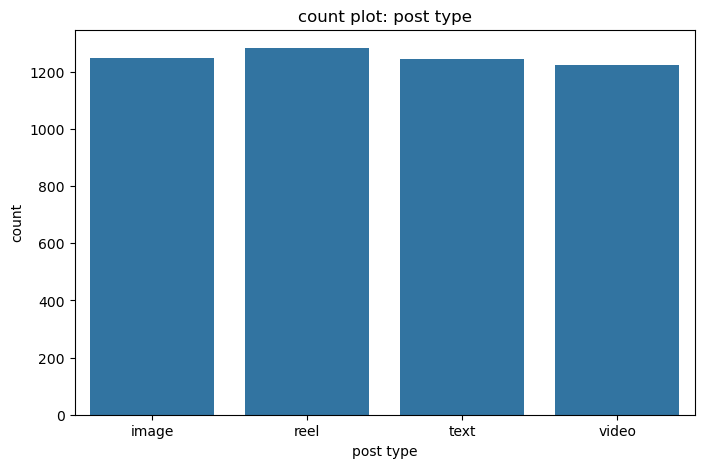

In [17]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='post_type')
plt.title('count plot: post type')
plt.xlabel('post type')
plt.ylabel('count')
plt.show()

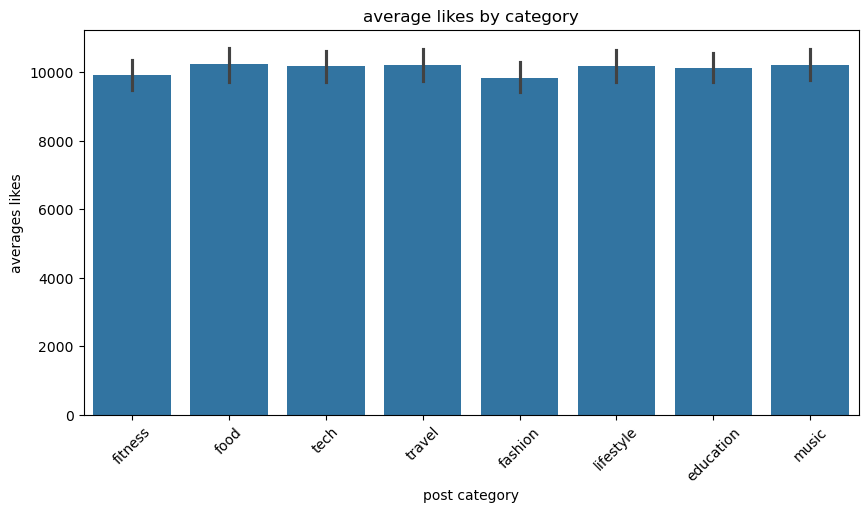

In [20]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='post_category', y='likes')
plt.title('average likes by category')
plt.xlabel('post category')
plt.ylabel('averages likes')
plt.xticks(rotation=45)
plt.show()

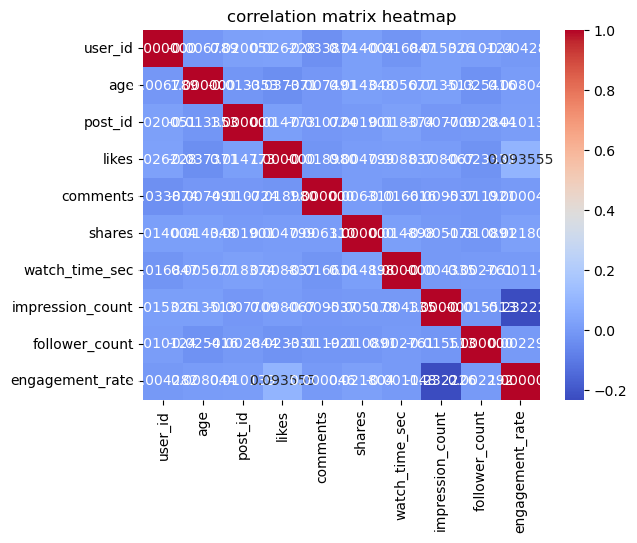

In [23]:
plt.Figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=['Float64','int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm',fmt='2f')
plt.title('correlation matrix heatmap')
plt.show()

In [24]:
!pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 2.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.7 MB 2.9 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.7 MB 2.4 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.7 MB 2.3 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.7 MB 2.3 MB/s eta 0:00:04
   ---------- ----------------------------- 2.6/9.7 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.6/9.7 MB 2.0 MB/s eta 0:00:04
   ------------ --------------------------- 3.1/9.7 MB 1.8 MB/s eta 0:00:04
   ------------ --------------------------- 3.1/9.7 MB 1.8 MB/s eta 0:00:04
   -------------- ----------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USER\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [25]:
import plotly.express as px
fig = px.scatter(df, x='impression_count', y='likes', color='post_category')
fig.show()

In [26]:
df.to_csv('cleaned_social_media_engagement.csv', index=False)

In [27]:
post_type_engagement = df.groupby('post_type')['engagement_rate'].mean().reset_index()
print(post_type_engagement)

  post_type  engagement_rate
0     image         0.895646
1      reel         0.783047
2      text         1.064549
3     video         1.122365


In [28]:
category_engagement = df.groupby('post_category')['engagement_rate'].mean().reset_index()
print(category_engagement)

  post_category  engagement_rate
0     education         0.844222
1       fashion         0.807109
2       fitness         0.865628
3          food         1.358628
4     lifestyle         1.091019
5         music         0.888803
6          tech         1.160475
7        travel         0.702223


In [29]:
age_engagement = df.groupby('age')['engagement_rate'].mean().reset_index()
print(age_engagement)

     age  engagement_rate
0   13.0         0.455583
1   14.0         1.003067
2   15.0         0.714170
3   16.0         1.226848
4   17.0         0.858763
5   18.0         0.888391
6   19.0         0.676687
7   20.0         0.515541
8   21.0         0.452752
9   22.0         0.586786
10  23.0         0.922448
11  24.0         2.897327
12  25.0         1.041681
13  26.0         0.501467
14  27.0         0.775328
15  28.0         0.385081
16  29.0         1.110432
17  30.0         1.270129
18  31.0         0.440684
19  32.0         0.581710
20  33.0         1.277557
21  34.0         0.557236
22  35.0         1.521596
23  36.0         0.609569
24  37.0         0.494109
25  38.0         1.247501
26  39.0         0.436184
27  40.0         0.930504
28  41.0         1.540070
29  42.0         1.350772
30  43.0         0.566439
31  44.0         0.795102
32  45.0         0.513521
33  46.0         0.663994
34  47.0         1.402015
35  48.0         1.675878
36  49.0         0.999235
37  50.0    

In [30]:
verified_engagement = df.groupby('is_verified')['engagement_rate'].mean().reset_index()
print(verified_engagement)

   is_verified  engagement_rate
0        False         0.954744
1         True         1.054250


In [31]:
df['posted_at'] = pd.to_datetime(df['posted_at'])
df['hour'] = df['posted_at']. dt.hour
time_engagement = df.groupby('hour')['impression_count'].mean().reset_index()
print(time_engagement)

   hour  impression_count
0     0        50013.7328


C:\Users\USER\AppData\Local\Temp\ipykernel_12152\1207875426.py:1: UserWarning:

Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



In [32]:
device_watch = df.groupby('device_type')['watch_time_sec'].mean().reset_index()
print(device_watch)

  device_type  watch_time_sec
0     desktop     3974.792521
1      mobile     4087.830760
2      tablet     3979.736429


In [33]:
sentiment_engagement = df.groupby('sentiment')['engagement_rate'].mean().reset_index()
print(sentiment_engagement)

  sentiment  engagement_rate
0  negative         1.038486
1   neutral         0.991170
2  positive         0.954800


In [34]:
sentiment_behaviour = df.groupby('sentiment')[['impression_count', 'watch_time_sec']].mean().reset_index()
print(sentiment_behaviour)

  sentiment  impression_count  watch_time_sec
0  negative      50191.960417     4054.639583
1   neutral      49515.971185     4031.823183
2  positive      49986.155734     3980.731274
